In [12]:
# Import the required libraries and locate the project.
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CASE_ID = 'C0010'
PROJECT_ROOT = Path.cwd().resolve()

# Move up until the project data directory is found.
while not (PROJECT_ROOT / 'data' / CASE_ID).is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError(f'Cannot find data/{CASE_ID} above the working directory.')
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / 'data' / CASE_ID
OUTPUT_DIR = PROJECT_ROOT / 'out' / CASE_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('项目目录:', PROJECT_ROOT)
print('数据目录:', DATA_DIR)
print('输出目录:', OUTPUT_DIR)


项目目录: D:\Workspace\eBATS
数据目录: D:\Workspace\eBATS\data\C0010
输出目录: D:\Workspace\eBATS\out\C0010


In [13]:
AMBIENT_C = 25  # Figure 16 condition (C).
INPUT_TEMPERATURE_UNIT = 'K'  # Report input unit.

MIN_SAMPLES = 100  # History validation.
START_TOLERANCE_S = 2.0  # Start-time tolerance (s).
END_TOLERANCE_S = 5.0  # End-time tolerance (s).

T_LIMIT = 45.0  # Feasibility and temperature limit lines (C).
DT_LIMIT = 5.0  # Feasibility and temperature-difference limit (C).
DPI = 900  # Figure export resolution.

# Mission metadata used for file loading and plotting.
MISSIONS = {
    'short': dict(
        name='Short-cruise / extended-hover (50 km)',
        abbr='SC-EH',
        folder='M050km_C0633s_H0300s_D1293s',
        cruise=633, hover=300, end=1293, km=50,
    ),
    'baseline': dict(
        abbr='REF',
        name='Baseline mission (100 km)',
        folder='M100km_C1380s_H0180s_D1920s',
        cruise=1380, hover=180, end=1920, km=100,
    ),
    'long': dict(
        abbr='EC-NH',
        name='Extended-cruise / normal-hover (120 km)',
        folder='M120km_C1680s_H0180s_D2220s',
        cruise=1680, hover=180, end=2220, km=120,
    ),
}

mission_table = pd.DataFrame.from_dict(MISSIONS, orient='index')

if not np.isfinite(mission_table[['cruise', 'hover', 'end', 'km']].to_numpy()).all():
    raise ValueError('任务参数必须为有限数值。')
if (mission_table[['cruise', 'hover', 'end', 'km']] <= 0).any().any():
    raise ValueError('任务时长和航程必须为正值。')

# Stages: take-off, ascent, acceleration, cruise, deceleration, descent, hover, landing.
# Indices 3 and 6 are replaced with each mission's cruise and hover durations.
common_stage_durations = np.array([6, 30, 144, 0, 144, 30, 0, 6], dtype=float)

short_durations = common_stage_durations.copy()
short_durations[3] = MISSIONS['short']['cruise']
short_durations[6] = MISSIONS['short']['hover']
MISSIONS['short']['stage_bounds'] = np.r_[0.0, np.cumsum(short_durations)]

baseline_durations = common_stage_durations.copy()
baseline_durations[3] = MISSIONS['baseline']['cruise']
baseline_durations[6] = MISSIONS['baseline']['hover']
MISSIONS['baseline']['stage_bounds'] = np.r_[0.0, np.cumsum(baseline_durations)]

long_durations = common_stage_durations.copy()
long_durations[3] = MISSIONS['long']['cruise']
long_durations[6] = MISSIONS['long']['hover']
MISSIONS['long']['stage_bounds'] = np.r_[0.0, np.cumsum(long_durations)]

if not np.isfinite(np.r_[short_durations, baseline_durations, long_durations]).all():
    raise ValueError('飞行阶段时长必须为有限数值。')
if np.min(np.r_[short_durations, baseline_durations, long_durations]) <= 0:
    raise ValueError('八个飞行阶段的时长都必须为正值。')
mission_table['Stage_total_s'] = [short_durations.sum(), baseline_durations.sum(), long_durations.sum()]
if not np.isclose(mission_table['Stage_total_s'], mission_table['end']).all():
    raise ValueError('阶段时长之和与任务总时长不一致。')

print(mission_table[['name', 'cruise', 'hover', 'end', 'km', 'Stage_total_s']].to_string())


                                             name  cruise  hover   end   km  Stage_total_s
short       Short-cruise / extended-hover (50 km)     633    300  1293   50         1293.0
baseline                Baseline mission (100 km)    1380    180  1920  100         1920.0
long      Extended-cruise / normal-hover (120 km)    1680    180  2220  120         2220.0


In [14]:
# List the operating conditions explicitly.
# Optional_empty=True permits skipping only the two documented empty LC conditions.
# Completed report pairs are loaded automatically; incomplete pairs raise an error.
case_table = pd.DataFrame([
    ('AC', 'short',    20, False),
    ('LC', 'short',    20, False),
    ('AC', 'short',    25, False),
    ('LC', 'short',    25, False),
    ('AC', 'short',    35, False),
    ('LC', 'short',    35, False),
    ('AC', 'baseline', 20, False),
    ('LC', 'baseline', 20, True),
    ('AC', 'baseline', 25, False),
    ('LC', 'baseline', 25, False),
    ('AC', 'baseline', 35, False),
    ('LC', 'baseline', 35, True),
    ('AC', 'long',     20, False),
    ('LC', 'long',     20, False),
    ('AC', 'long',     25, False),
    ('LC', 'long',     25, False),
    ('AC', 'long',     35, False),
    ('LC', 'long',     35, False),
], columns=['Cooling', 'Mission_key', 'Ambient_C', 'Optional_empty'])

if case_table.duplicated(['Cooling', 'Mission_key', 'Ambient_C']).any():
    raise ValueError('工况清单存在重复项。')
if not case_table['Mission_key'].isin(mission_table.index).all():
    raise ValueError('工况清单包含未定义的任务。')
if not case_table['Cooling'].isin(['AC', 'LC']).all():
    raise ValueError('当前图只支持 AC 与 LC 工况。')
if not case_table['Ambient_C'].isin([20, 25, 35]).all():
    raise ValueError('当前 Figure 17 只绘制 20/25/35 °C。')

# Show relative directories in the inventory to help locate missing reports.
case_table['Folder'] = case_table['Mission_key'].map(mission_table['folder'])
case_table['Relative_directory'] = (
    case_table['Cooling'] + '/' + case_table['Folder']
    + '/T' + case_table['Ambient_C'].astype(str).str.zfill(3) + 'C'
)
print(case_table[['Cooling', 'Mission_key', 'Ambient_C', 'Relative_directory', 'Optional_empty']].to_string(index=False))


Cooling Mission_key  Ambient_C                   Relative_directory  Optional_empty
     AC       short         20 AC/M050km_C0633s_H0300s_D1293s/T020C           False
     LC       short         20 LC/M050km_C0633s_H0300s_D1293s/T020C           False
     AC       short         25 AC/M050km_C0633s_H0300s_D1293s/T025C           False
     LC       short         25 LC/M050km_C0633s_H0300s_D1293s/T025C           False
     AC       short         35 AC/M050km_C0633s_H0300s_D1293s/T035C           False
     LC       short         35 LC/M050km_C0633s_H0300s_D1293s/T035C           False
     AC    baseline         20 AC/M100km_C1380s_H0180s_D1920s/T020C           False
     LC    baseline         20 LC/M100km_C1380s_H0180s_D1920s/T020C            True
     AC    baseline         25 AC/M100km_C1380s_H0180s_D1920s/T025C           False
     LC    baseline         25 LC/M100km_C1380s_H0180s_D1920s/T025C           False
     AC    baseline         35 AC/M100km_C1380s_H0180s_D1920s/T035C         

In [15]:
# Read max.out and min.out directly in one case-loading loop.
RAW_CFD_REPORTS = {}
load_status = []

for item in case_table.itertuples(index=False):
    key = (item.Cooling, item.Mission_key, item.Ambient_C)
    case_directory = DATA_DIR / item.Relative_directory
    max_file = case_directory / 'max.out'
    min_file = case_directory / 'min.out'

    if not case_directory.parent.is_dir():
        raise FileNotFoundError(f'缺少任务目录: {case_directory.parent}')
    if max_file.is_file() and min_file.is_file():
        # Read the maximum-temperature report using the third-line column names.
        max_header = re.findall(r'"([^"]+)"', max_file.read_text(encoding='utf-8-sig').splitlines()[2])
        max_report = pd.read_csv(
            max_file, sep=r'\s+', skiprows=3, names=max_header,
            encoding='utf-8-sig', dtype=float, float_precision='round_trip',
        )
        max_report = max_report[['flow-time', 'max']].copy()

        # Read the minimum-temperature report in the same way.
        min_header = re.findall(r'"([^"]+)"', min_file.read_text(encoding='utf-8-sig').splitlines()[2])
        min_report = pd.read_csv(
            min_file, sep=r'\s+', skiprows=3, names=min_header,
            encoding='utf-8-sig', dtype=float, float_precision='round_trip',
        )
        min_report = min_report[['flow-time', 'min']].copy()

        # Convert both temperature columns to Celsius.
        if INPUT_TEMPERATURE_UNIT == 'K':
            max_report['max'] -= 273.15
            min_report['min'] -= 273.15

        # Sort by time, retain the last duplicate, and use standard column names.
        max_report = max_report.sort_values('flow-time', kind='stable').drop_duplicates('flow-time', keep='last')
        min_report = min_report.sort_values('flow-time', kind='stable').drop_duplicates('flow-time', keep='last')
        max_report.columns = ['time_s', 'Temperature_C']
        min_report.columns = ['time_s', 'Temperature_C']
        RAW_CFD_REPORTS[key] = {
            'max_report': max_report.reset_index(drop=True),
            'min_report': min_report.reset_index(drop=True),
        }
        load_status.append('Loaded')
    elif item.Optional_empty and (
        not case_directory.exists() or
        (case_directory.is_dir() and not any(case_directory.iterdir()))
    ):
        load_status.append('Skipped empty')
    else:
        raise FileNotFoundError(f'必须同时提供 max.out 和 min.out: {case_directory}')

case_table['Status'] = load_status
print(case_table[['Cooling', 'Mission_key', 'Ambient_C', 'Status']].to_string(index=False))
print('成功读取:', int((case_table['Status'] == 'Loaded').sum()))
print('跳过空工况:', int((case_table['Status'] == 'Skipped empty').sum()))


Cooling Mission_key  Ambient_C Status
     AC       short         20 Loaded
     LC       short         20 Loaded
     AC       short         25 Loaded
     LC       short         25 Loaded
     AC       short         35 Loaded
     LC       short         35 Loaded
     AC    baseline         20 Loaded
     LC    baseline         20 Loaded
     AC    baseline         25 Loaded
     LC    baseline         25 Loaded
     AC    baseline         35 Loaded
     LC    baseline         35 Loaded
     AC        long         20 Loaded
     LC        long         20 Loaded
     AC        long         25 Loaded
     LC        long         25 Loaded
     AC        long         35 Loaded
     LC        long         35 Loaded
成功读取: 18
跳过空工况: 0


In [16]:
# Process loaded reports: check coverage, align times, and calculate temperature differences and extrema.
CFD_HISTORIES = {}
CFD_EXTREMA = {}
summary_rows = []

for key, reports in RAW_CFD_REPORTS.items():
    cooling, mission_key, ambient = key
    mission = MISSIONS[mission_key]
    max_report = reports['max_report']
    min_report = reports['min_report']

    # 1. Check the time coverage of both reports.
    high_time = max_report['time_s'].to_numpy()
    low_time = min_report['time_s'].to_numpy()
    if len(high_time) < MIN_SAMPLES or len(low_time) < MIN_SAMPLES:
        raise ValueError(f'有效记录不足: {key}')
    if high_time[0] > START_TOLERANCE_S or low_time[0] > START_TOLERANCE_S:
        raise ValueError(f'任务起点缺少温度历史: {key}')

    # 2. Restrict interpolation to the shared mission time interval.
    start = max(0.0, high_time[0], low_time[0])
    end = min(mission['end'], high_time[-1], low_time[-1])
    time = np.union1d(high_time, low_time)
    time = time[(time >= start) & (time <= end)]
    if len(time) < MIN_SAMPLES or time[0] > START_TOLERANCE_S:
        raise ValueError(f'共同时间范围不足: {key}')
    if abs(time[-1] - mission['end']) > END_TOLERANCE_S:
        raise ValueError(f'任务终点缺少温度历史: {key}')

    # 3. Align the upper and lower temperature bounds.
    upper = np.interp(time, high_time, max_report['Temperature_C'].to_numpy())
    lower = np.interp(time, low_time, min_report['Temperature_C'].to_numpy())
    if np.any(upper < lower):
        raise ValueError(f'最高温度低于最低温度: {key}')
    difference = upper - lower
    midpoint = (upper + lower) / 2  # Boundary midpoint, not the mean battery temperature.

    # 4. Find maximum temperature and maximum temperature difference independently and record their times.
    peak_index = int(np.argmax(upper))
    difference_index = int(np.argmax(difference))
    peak = {
        'Tmax_C': float(upper[peak_index]),
        'Tmax_time_s': float(time[peak_index]),
        'DTmax_C': float(difference[difference_index]),
        'DTmax_time_s': float(time[difference_index]),
        'DTmax_upper_C': float(upper[difference_index]),
        'DTmax_lower_C': float(lower[difference_index]),
    }

    # 5. Store complete histories and mission-level summary results.
    CFD_HISTORIES[key] = {
        'time_s': time, 'Tmax_C': upper, 'Tmin_C': lower,
        'Tmid_C': midpoint, 'DT_C': difference, 'source': 'CFD',
    }
    CFD_EXTREMA[key] = peak
    summary_rows.append({
        'Mission': mission['name'], 
        'Mission_key': mission_key,
        'Cooling': cooling, 
        'Ambient_C': ambient,
        'Source': 'CFD', **peak,
        'T_margin_C': T_LIMIT - peak['Tmax_C'],
        'DT_margin_C': DT_LIMIT - peak['DTmax_C'],
        'Feasible': peak['Tmax_C'] <= T_LIMIT and peak['DTmax_C'] <= DT_LIMIT,
        'hover': mission['hover'],
        'end': mission['end'],
    })

if set(CFD_HISTORIES) != set(RAW_CFD_REPORTS):
    raise ValueError('处理后的工况与已读取报告不一致。')
df_fig17 = pd.DataFrame(summary_rows)
print(df_fig17[['Mission', 'Cooling', 'Ambient_C', 'Tmax_C', 'DTmax_C', 'Feasible']].to_string(index=False))


                                Mission Cooling  Ambient_C    Tmax_C  DTmax_C  Feasible
  Short-cruise / extended-hover (50 km)      AC         20 45.748588 8.181427     False
  Short-cruise / extended-hover (50 km)      LC         20 34.637815 4.247444      True
  Short-cruise / extended-hover (50 km)      AC         25 50.326540 8.058525     False
  Short-cruise / extended-hover (50 km)      LC         25 39.380405 4.180210      True
  Short-cruise / extended-hover (50 km)      AC         35 60.122509 8.120047     False
  Short-cruise / extended-hover (50 km)      LC         35 49.110843 4.143287     False
              Baseline mission (100 km)      AC         20 39.339352 5.147598     False
              Baseline mission (100 km)      LC         20 32.279162 2.919211      True
              Baseline mission (100 km)      AC         25 44.316001 4.932085      True
              Baseline mission (100 km)      LC         25 37.000675 2.864107      True
              Baseline mission (

In [17]:
# Figure 16: select the six histories and extrema at the configured ambient temperature.
# Prepare plotting inputs here so each plot cell can run independently.
FIG16_DATA = {
    ('short', 'AC'): CFD_HISTORIES[('AC', 'short', AMBIENT_C)],
    ('short', 'LC'): CFD_HISTORIES[('LC', 'short', AMBIENT_C)],
    ('baseline', 'AC'): CFD_HISTORIES[('AC', 'baseline', AMBIENT_C)],
    ('baseline', 'LC'): CFD_HISTORIES[('LC', 'baseline', AMBIENT_C)],
    ('long', 'AC'): CFD_HISTORIES[('AC', 'long', AMBIENT_C)],
    ('long', 'LC'): CFD_HISTORIES[('LC', 'long', AMBIENT_C)],
}
FIG16_EXTREMA = {
    ('short', 'AC'): CFD_EXTREMA[('AC', 'short', AMBIENT_C)],
    ('short', 'LC'): CFD_EXTREMA[('LC', 'short', AMBIENT_C)],
    ('baseline', 'AC'): CFD_EXTREMA[('AC', 'baseline', AMBIENT_C)],
    ('baseline', 'LC'): CFD_EXTREMA[('LC', 'baseline', AMBIENT_C)],
    ('long', 'AC'): CFD_EXTREMA[('AC', 'long', AMBIENT_C)],
    ('long', 'LC'): CFD_EXTREMA[('LC', 'long', AMBIENT_C)],
}
FIG16_TABLE = df_fig17.loc[df_fig17['Ambient_C'] == AMBIENT_C].reset_index(drop=True).copy()
if len(FIG16_TABLE) != 6:
    raise ValueError('Figure 16 必须包含三种任务、两种冷却方案的六组数据。')

print('Figure 16 工况数:', len(FIG16_TABLE))
print('Figure 17 工况数:', len(df_fig17))
print('可行工况数:', int(df_fig17['Feasible'].sum()))


Figure 16 工况数: 6
Figure 17 工况数: 18
可行工况数: 7


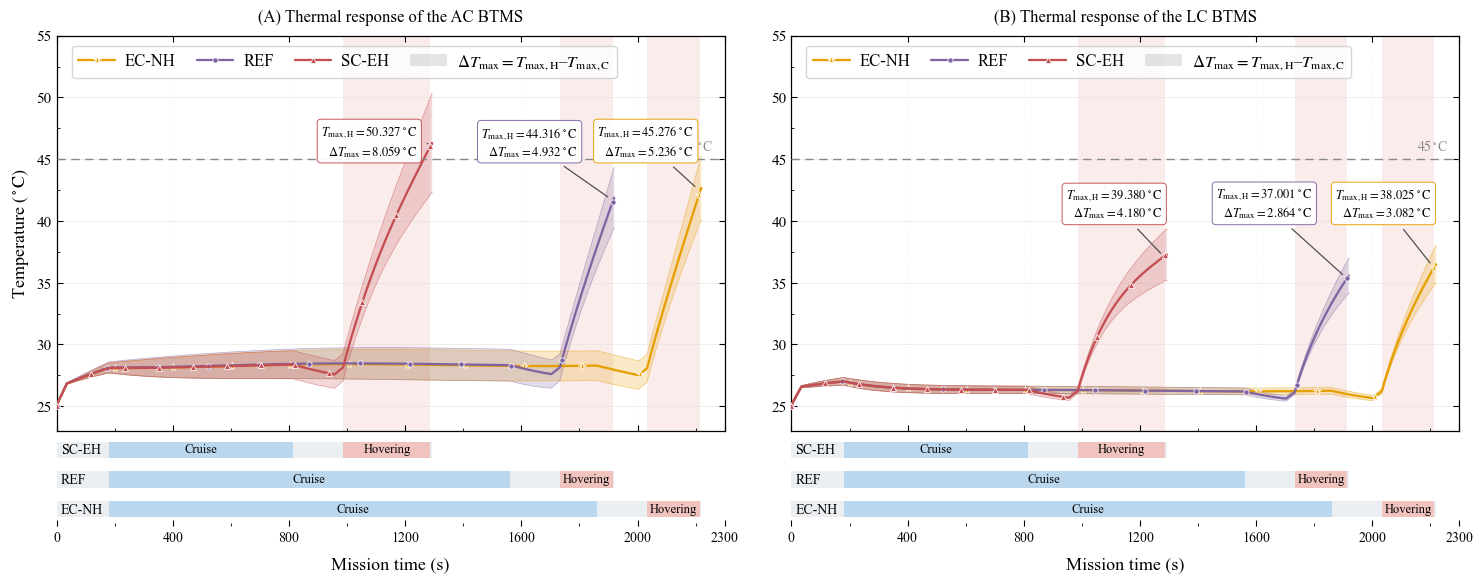

PNG: D:\Workspace\eBATS\out\C0010\C0010R01_PARK25_ACLC_INTG_CFD_CMP_mission_thermal_response.png
PDF: D:\Workspace\eBATS\out\C0010\C0010R01_PARK25_ACLC_INTG_CFD_CMP_mission_thermal_response.pdf


In [31]:
# Figure 16: create the figure, plot curves, then add bands and annotations.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Patch
from matplotlib.ticker import AutoMinorLocator

font_size = 12
plt.rcParams.update({
    'font.family': 'Times New Roman',
    'mathtext.fontset': 'stix',
    'font.size': font_size,
    'axes.labelsize': font_size,
    'axes.titlesize': font_size,
    'xtick.labelsize': font_size - 1,
    'ytick.labelsize': font_size - 1,
    'axes.linewidth': 0.9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'axes.unicode_minus': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

# Create the canvas.
fig16, axes = plt.subplots(2, 2, figsize=(15.5, 7.0), facecolor='white', sharex='col', gridspec_kw=dict(height_ratios=[4.5, 1.05], wspace=0.1, hspace=0.01))
fig16.subplots_adjust(left=0.085, right=0.99, bottom=0.19, top=0.89)
ax_ac, ax_lc = axes[0]
ax_stage_ac, ax_stage_lc = axes[1]

ac_short = FIG16_DATA[('short', 'AC')]
ac_baseline = FIG16_DATA[('baseline', 'AC')]
ac_long = FIG16_DATA[('long', 'AC')]
lc_short = FIG16_DATA[('short', 'LC')]
lc_baseline = FIG16_DATA[('baseline', 'LC')]
lc_long = FIG16_DATA[('long', 'LC')]

curve_dict = {
    'ac_long': {
        "mission": "Long", 
        "abbr": MISSIONS["long"]["abbr"],
        "cooling": "AC", 
        "data": ac_long,
        "peak": FIG16_EXTREMA[('long', 'AC')],
        "stage_bounds": MISSIONS["long"]['stage_bounds'],
        "offset_text": (-25, 0),
        "y_stage": 0},    
    'ac_baseline': {
        "mission": "Baseline", 
        "abbr": MISSIONS["baseline"]["abbr"],
        "cooling": "AC", 
        "data": ac_baseline,
        "peak": FIG16_EXTREMA[('baseline', 'AC')],
        "stage_bounds": MISSIONS["baseline"]['stage_bounds'],
        "offset_text": (-125, 0),
        "y_stage": 1},
    'ac_short': {
        "mission": "Short", 
        "abbr": MISSIONS["short"]["abbr"],
        "cooling": "AC", 
        "data": ac_short,
        "peak": FIG16_EXTREMA[('short', 'AC')],
        "stage_bounds": MISSIONS["short"]['stage_bounds'],
        "offset_text": (-50, 0),
        "y_stage": 2},
    'lc_long': {
        "mission": "Long", 
        "abbr": MISSIONS["long"]["abbr"],
        "cooling": "LC", 
        "data": lc_long,
        "peak": FIG16_EXTREMA[('long', 'LC')],
        "stage_bounds": MISSIONS["long"]['stage_bounds'],
        "offset_text": (-15, -5),
        "y_stage": 0},
    'lc_baseline': {
        "mission": "Baseline", 
        "abbr": MISSIONS["baseline"]["abbr"],
        "cooling": "LC", 
        "data": lc_baseline,
        "peak": FIG16_EXTREMA[('baseline', 'LC')],
        "offset_text": (-125, -5),
        "stage_bounds": MISSIONS["baseline"]['stage_bounds'],
        "y_stage": 1},
    'lc_short': {
        "mission": "Short", 
        "abbr": MISSIONS["short"]["abbr"],
        "cooling": "LC", 
        "data": lc_short,
        "peak": FIG16_EXTREMA[('short', 'LC')],
        "offset_text": (-15, -5),
        "stage_bounds": MISSIONS["short"]['stage_bounds'],
        "y_stage": 2},
}


line_style = {
    'Short': dict(color='#C44E52', marker='^', markersize=4.2),
    'Baseline': dict(color='#8064A2', marker='o', markersize=3.8),
    'Long': dict(color='#E69F00', marker='*', markersize=5.8),
}
curve_style = dict(linestyle='-', linewidth=1.65, markeredgecolor='white', markeredgewidth=0.55, solid_capstyle='round', zorder=5)

band_style = dict(alpha=0.22, edgecolor='none', zorder=2)
boundary_style = dict(linewidth=0.50, alpha=0.50, zorder=3)
# Add six independent extrema callouts; edit xytext to move a label.
ellipse_style = dict(width=95.0, facecolor='none', linewidth=1.35, linestyle=(0, (3.0, 2.2)), zorder=12)
box_style = dict(boxstyle='round,pad=0.30', facecolor='white', linewidth=0.7, alpha=0.95)
callout_style = dict(xycoords='data', textcoords='data', ha='right', va='bottom', fontsize=font_size - 3, annotation_clip=False, zorder=15,
                    arrowprops=dict(arrowstyle='-', color='#505050', linewidth=0.9, shrinkA=4, shrinkB=2))
bar_style = dict(height=0.54, edgecolor='none')
stage_text_style = dict(ha='center', va='center', fontsize=font_size - 3)
hover_style = dict(color='#F0C3BE', alpha=0.30, linewidth=0, zorder=0)


# Add the design limit.
limit_style = dict(color='#888888', linewidth=1.0, linestyle=(0, (6, 4)), zorder=6)
limit_text_style = dict(xycoords=('axes fraction', 'data'), xytext=(-8, 4), textcoords='offset points', ha='right', va='bottom', fontsize=font_size - 2, color='#888888')

# Set axes and grids.
time_max = max(2300, MISSIONS['short']['end'], MISSIONS['baseline']['end'], MISSIONS['long']['end'])
all_lower = np.concatenate((ac_short['Tmin_C'], ac_baseline['Tmin_C'], ac_long['Tmin_C'], lc_short['Tmin_C'], lc_baseline['Tmin_C'], lc_long['Tmin_C']))
limits = dict(xlim=(0, time_max), ylim=(min(24, float(np.floor(all_lower.min() - 1))), max(55, float(np.ceil(FIG16_TABLE['Tmax_C'].max() + 1)))))
limits['xticks'] = np.r_[np.arange(0, time_max, 400), time_max]
limits['yticks'] = np.arange(np.ceil(limits['ylim'][0] / 5) * 5, limits['ylim'][1] + 0.01, 5)

stage_limits = dict(ylim=(-0.55, 2.55), yticks=[2,1,0], yticklabels=['Short', 'Baseline', 'Long'])
# Plot the six midpoint curves.

y_annotation = 45

for key, value in curve_dict.items():
    ax = ax_ac if value['cooling'] == 'AC' else ax_lc
    ax_stage = ax_stage_ac if value['cooling'] == 'AC' else ax_stage_lc
    
    val_mid = value['data']['Tmid_C']
    val_max = value['data']['Tmax_C']
    val_min = value['data']['Tmin_C']
    val_time = value['data']['time_s']
    mission_name = value['mission']
    mission_abbr = value['abbr']
    
    line, = ax.plot(
        val_time,
        val_mid,
        markevery=max(1, len(value['data']['time_s']) // 11),
        label=mission_abbr,
        **line_style[mission_name],
        **curve_style
    )
    
    ax.fill_between(
        val_time,
        val_min,
        val_max,
        color=line_style[mission_name]['color'],
        **band_style
    )
    
    ax.plot(
        val_time,
        np.column_stack((val_max, val_min)),
        color=line_style[mission_name]['color'],
        **boundary_style
    )
    
    stage_bounds = value['stage_bounds']
    
    # Add the red hovering backgrounds using the same boundaries as the timelines.
    ax.axvspan(stage_bounds[6], stage_bounds[7], **hover_style)

    peak = value['peak']
    center_x = peak['DTmax_time_s']
    center_y = (peak['DTmax_upper_C'] + peak['DTmax_lower_C']) / 2
    offset_x, offset_y = value["offset_text"]
    
    label = rf'$T_\mathrm{{\max, H}}={peak["Tmax_C"]:.3f}\,^\circ\mathrm{{C}}$' + '\n' + rf'$\Delta T_\mathrm{{\max}}={peak["DTmax_C"]:.3f}\,^\circ\mathrm{{C}}$'
    # print(f'line color for mission {mission_name} is', line_style)
    # ax.add_patch(Ellipse((center_x, center_y), height=peak['DTmax_C'] + 1.20, 
    # edgecolor=line_style[mission_name]['color'], **ellipse_style))    
  
    # Annotation for the peak temperature at the center of the ellipse
    ax.annotate(label, xy=(center_x -15, center_y), xytext=(center_x + offset_x, y_annotation + offset_y), bbox=dict(box_style, edgecolor=line_style[mission_name]['color']), **callout_style)
    
    y_stage = value['y_stage']
    
    ax_stage.barh(y_stage, stage_bounds[-1] - stage_bounds[0], left=stage_bounds[0], color='#ECEFF2', **bar_style)
    ax_stage.barh(y_stage, stage_bounds[4] - stage_bounds[3], left=stage_bounds[3], color='#BBD7ED', **bar_style)
    ax_stage.barh(y_stage, stage_bounds[7] - stage_bounds[6], left=stage_bounds[6], color='#F0C3BE', **bar_style)
    
    ax_stage.text(stage_bounds[0:3].mean(), y_stage, mission_abbr, ha='left', va='center',fontsize=font_size-2)
    
    ax_stage.text(stage_bounds[3:5].mean(), y_stage, 'Cruise', **stage_text_style)
    ax_stage.text(stage_bounds[6:8].mean(), y_stage, 'Hovering', **stage_text_style)
    
    
axes = [(ax_ac, ax_stage_ac), (ax_lc, ax_stage_lc)]

legend_style = dict(loc='upper left', bbox_to_anchor=(0.01, 0.995), ncol=4, frameon=True, alignment='left', fontsize=font_size,
                    handlelength=2.2, handletextpad=0.6, columnspacing=1.25)
band_handle = Patch(facecolor='#888888', alpha=0.22, label=r'$\Delta T_\max = T_\mathrm{\max,H}$–$T_\mathrm{\max,C}$')

for ax, ax_stage in axes:
    ax.axhline(T_LIMIT, **limit_style)
    ax.annotate(rf'${T_LIMIT:g}^\circ$C', xy=(1, T_LIMIT), **limit_text_style)
    ax.set(**limits)
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.tick_params(direction='in', top=True, right=True)
    ax.grid(axis='y', color='0.88', linewidth=0.6, alpha=0.65)
    ax.grid(axis='x', color='0.91', linewidth=0.55, linestyle=':', alpha=0.55)
    ax.set_axisbelow(True)
    
    title = ''
    if(ax is ax_ac):
        ax.set_ylabel(r'Temperature ($^\circ\mathrm{C}$)', fontsize=font_size + 1)
        title = '(A) Thermal response of the AC BTMS'
    elif(ax is ax_lc):        
        title = '(B) Thermal response of the LC BTMS'
    ax.set_title(title, pad=10)

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles = [*handles, band_handle], labels = [*labels, band_handle.get_label()], **legend_style)  
    
    ax_stage.set(**stage_limits)
    ax_stage.set_xlabel('Mission time (s)', fontsize=font_size + 1, labelpad=9)
    ax_stage.tick_params(axis='x', direction='in', labelsize=font_size - 2)
    ax_stage.tick_params(axis='y', direction='in', labelsize=font_size - 2)

    ax_stage.set_yticklabels([])    
    # stage_labels = ax_stage.get_yticklabels()
    # stage_labels[0].set_color(line_style['short']['color'])
    # stage_labels[1].set_color(line_style['baseline']['color'])
    # stage_labels[2].set_color(line_style['long']['color'])
    
    # ax_stage.grid(axis='x', color='0.89', linewidth=0.55, linestyle=':', alpha=0.65)
    # ax_stage.grid(axis='y', color='0.88', linewidth=0.6, alpha=0.65)
    
    ax_stage.set_axisbelow(True)
    ax_stage.spines[:].set_visible(False)


# Save and display.
figure_name = f'{CASE_ID}R01_PARK{AMBIENT_C:02d}_ACLC_INTG_CFD_CMP_mission_thermal_response'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
png_file = OUTPUT_DIR / f'{figure_name}.png'
pdf_file = OUTPUT_DIR / f'{figure_name}.pdf'
fig16.savefig(png_file, dpi=DPI, bbox_inches='tight', facecolor='white')
fig16.savefig(pdf_file, bbox_inches='tight', facecolor='white')
plt.show()
print('PNG:', png_file)
print('PDF:', pdf_file)


Processing group with 3 cases: cooling=AC, ambient=20
Processing group with 3 cases: cooling=LC, ambient=20
Processing group with 3 cases: cooling=AC, ambient=25
Processing group with 3 cases: cooling=LC, ambient=25
Processing group with 3 cases: cooling=AC, ambient=35
Processing group with 3 cases: cooling=LC, ambient=35
plotting an arrow from[(np.float64(36.00067499444083), np.float64(2.8641069649308974))] to [(np.float64(38.38040453243974), np.float64(4.180210294139897))], mean at [[37.19053976  3.52215863]]
plotting an arrow from[(np.float64(38.300674994440826), np.float64(2.6641069649308973))] to [(np.float64(39.12484415061554), np.float64(3.081531607162219))], mean at [[38.71275957  2.87281929]]


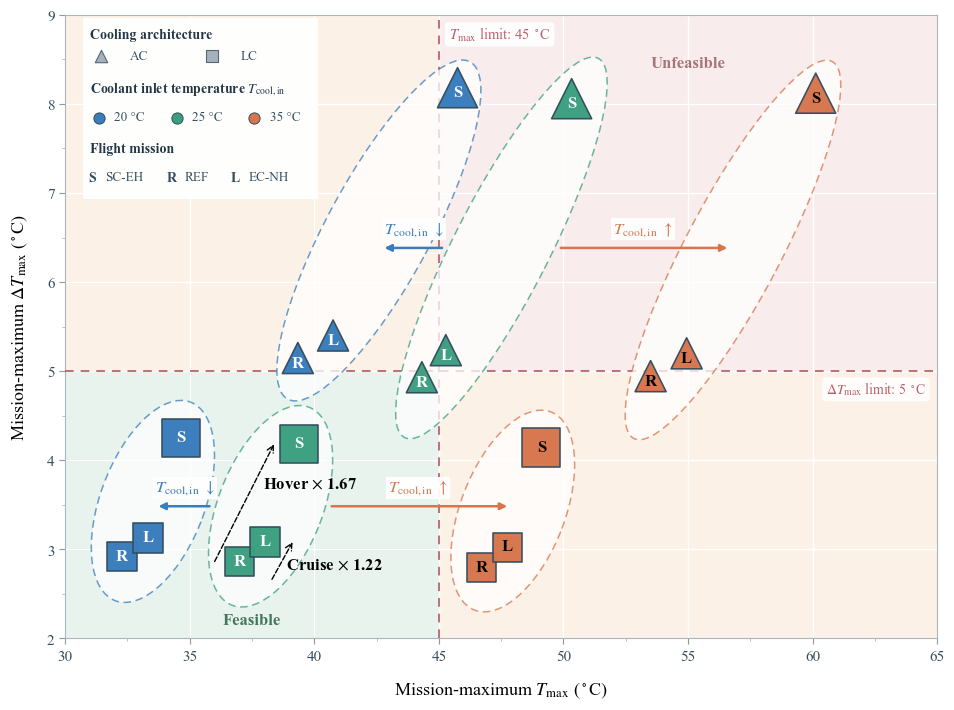

PNG: D:\Workspace\eBATS\out\C0010\C0010R01_PARK25_ACLC_INTG_CFD_CMP_thermal_feasibility.png
PDF: D:\Workspace\eBATS\out\C0010\C0010R01_PARK25_ACLC_INTG_CFD_CMP_thermal_feasibility.pdf


In [51]:
# Figure 17: create the figure, plot cases, then add regions, outlines, arrows, and legends.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Ellipse, FancyArrowPatch
from matplotlib.ticker import AutoMinorLocator
from matplotlib.text import OffsetFrom
from matplotlib.transforms import Affine2D

font_size = 12

plt.rcParams.update({
    'font.family': 'Times New Roman',
    'mathtext.fontset': 'stix',
    'font.size': font_size,
    'axes.labelsize': font_size,
    'xtick.labelsize': font_size - 1,
    'ytick.labelsize': font_size - 1,
    'axes.linewidth': 0.9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'axes.unicode_minus': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

# Create the canvas.
revision = 'R01'
figure_name = f'{CASE_ID}{revision}_PARK25_ACLC_INTG_CFD_CMP_thermal_feasibility'

fig17 = plt.figure(figsize=(10.2, 7.7), facecolor='white')
ax = fig17.add_axes([0.115, 0.145, 0.855, 0.81])
panel = ax.inset_axes([0.02, 0.69, 0.27, 0.29], zorder=10)

# Select data and define the operating conditions.
cooling_markers = {'AC': {'marker':'^', 'area':500}, 'LC': {'marker':'s', 'area':450}}
ambient_colors = {20: '#397DBC', 25: '#3B9F80', 35: '#D8754D'}

mission_letters = {
    MISSIONS['short']['name']: 'S',
    MISSIONS['baseline']['name']: 'R',
    MISSIONS['long']['name']: 'L',
}

df = df_fig17.copy()
df['Mission_letter'] = df['Mission'].map(mission_letters)

xmin, xmax = 30.0, 65.0
ymin, ymax = 2.0, 9.0
limits = dict(xlim=(xmin, xmax), ylim=(ymin, ymax), xticks=np.arange(30, 66, 5), yticks=np.arange(2, 10, 1))

# Visual group boundaries: center x/y, width, height (axes fractions), and angle (degrees).
# These outlines group cases; they do not represent confidence or data ranges.
outline_layout = {
    ('AC', 20): (0.41691240, 0.69255160, 0.45, 0.12, 62.418560),
    ('AC', 25): (0.55739851, 0.67193661, 0.50, 0.11, 63.687777),
    ('AC', 35): (0.82289888, 0.66947892, 0.50, 0.11, 62.992783),
    ('LC', 25): (0.29270306, 0.36674643, 0.25, 0.12, 69.571183),
    ('LC', 20): (0.15776756, 0.37244055, 0.25, 0.12, 70.149811),
    ('LC', 35): (0.57040914, 0.36110930, 0.25, 0.12, 69.786482),
}

plot_dict = {}

for (cooling, ambient), group in df.groupby(['Cooling', 'Ambient_C'], sort=False):
   
    plot_dict[(cooling, ambient)] = {
        'data': group,
        'marker': cooling_markers[cooling]['marker'],
        'area': cooling_markers[cooling]['area'],
        'color': ambient_colors[ambient],
        'outline': outline_layout[(cooling, ambient)],
    }

# Plot each operating-condition group and its mission letters.

# Define styles before adding plot elements.
scatter_style = dict(edgecolor='#344D5C', linewidth=1.15, alpha=0.98, zorder=5)
marker_text_style = dict(textcoords='offset points', ha='center', va='center', fontsize=font_size, fontweight='bold', zorder=6)

# determine the area based on the duration of hover stage
# get the hover duration of the base mission
hover_ref = MISSIONS['baseline']['hover']
end_ref = MISSIONS['baseline']['end']
ratio_hover_ref = hover_ref / end_ref

for key, value in plot_dict.items():
    cooling, ambient = key
    group = value['data']

    print(f"Processing group with {len(group)} cases: cooling={cooling}, ambient={ambient}")
    val_temperature = group['Tmax_C']
    val_difference = group['DTmax_C']
    area_ref = value['area']
    
    areas = []
    for item in group.itertuples(index=False):
        hover_ratio = item.hover / hover_ref
        area = area_ref * hover_ratio  # Example scaling factor for the area.
        areas.append(area)
        
    ax.scatter(
        val_temperature,
        val_difference,
        marker=value['marker'],
        color=value['color'],
        s=areas,
        **scatter_style
    )

    for item in group.itertuples(index=False):
        offset = (0, -4) if cooling == 'AC' else (0, 0)        
        text_color = 'black' if ambient == 35 else 'white'

        ax.annotate(
            item.Mission_letter,
            (item.Tmax_C, item.DTmax_C),
            xytext=offset,
            color=text_color,
            **marker_text_style
        )

# Add the four constraint-region backgrounds.
regions = [
    (xmin, ymin, T_LIMIT - xmin, DT_LIMIT - ymin, '#E7F3EC'),
    (xmin, DT_LIMIT, T_LIMIT - xmin, ymax - DT_LIMIT, '#FCF1E7'),
    (T_LIMIT, ymin, xmax - T_LIMIT, DT_LIMIT - ymin, '#FCF1E7'),
    (T_LIMIT, DT_LIMIT, xmax - T_LIMIT, ymax - DT_LIMIT, '#F8ECEC'),
]

background_style = dict(edgecolor='none', zorder=0)
for x, y, width, height, color in regions:
    ax.add_patch(
        Rectangle((x, y), width, height, facecolor=color, **background_style)
    )

# Add limit lines and region labels.
limit_style = dict(color='#B75E66', linewidth=1.25, linestyle=(0, (5, 4)), zorder=3)
ax.axvline(T_LIMIT, **limit_style)
ax.axhline(DT_LIMIT, **limit_style)

ax.annotate(
    rf'$T_{{\max}}$ limit: {T_LIMIT:g} $^\circ$C',
    (T_LIMIT, ymax),
    xytext=(7, -8),
    textcoords='offset points',
    ha='left',
    va='top',
    color=limit_style['color'],
    fontsize=font_size - 1.5,
    bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.95),
    zorder=4
)

ax.annotate(
    rf'$\Delta T_{{\max}}$ limit: {DT_LIMIT:g} $^\circ$C',
    (xmax, DT_LIMIT),
    xytext=(-8, -7),
    textcoords='offset points',
    ha='right',
    va='top',
    color=limit_style['color'],
    fontsize=font_size - 2,
    bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.9),
    zorder=4
)

region_labels = [
    ((xmin + T_LIMIT) / 2, ymin + 0.20, 'Feasible', '#43765B'),
    ((T_LIMIT + xmax) / 2, ymax - 0.55, 'Unfeasible', '#A77575'),
]

region_text_style = dict(ha='center', va='center', fontsize=font_size, fontweight='bold')

for x, y, label, color in region_labels:
    ax.text(x, y, label, color=color, **region_text_style)

# Set axes and grids.
ax.set(**limits)

ax.set_xlabel(r'Mission-maximum $T_{\max}$ ($^\circ$C)', fontsize=font_size + 1, labelpad=12)
ax.set_ylabel(r'Mission-maximum $\Delta T_{\max}$ ($^\circ$C)', fontsize=font_size + 1, labelpad=12)

for axis in (ax.xaxis, ax.yaxis):
    axis.set_minor_locator(AutoMinorLocator(2))

ax.tick_params(which='major', direction='out', length=4, color='#8B99A2', labelcolor='#344D5C', top=False, right=False)
ax.tick_params(which='minor', direction='out', length=2, color='#AAB5BD')

ax.grid(which='major', color='white', linewidth=0.95)
ax.set_axisbelow(True)

ax.spines[:].set_color('#AAB5BD')
ax.spines[:].set_linewidth(0.8)

# Add the six group outlines using their fixed layout.
# The layout uses the original 28-63 C / 0-9.5 C reference coordinates.
outline_style = dict(facecolor='white', fill=True, linewidth=1.1, linestyle=(0, (5, 3)), alpha=0.75, zorder=3)
outline_transform = Affine2D().scale(35, 9.5).translate(28, 0) + ax.transData
group_outlines = {}

for key, value in plot_dict.items():
    cx, cy, width, height, angle = value['outline']

    outline = Ellipse(
        (cx, cy),
        width=width,
        height=height,
        angle=angle,
        transform=outline_transform,
        edgecolor=value['color'],
        **outline_style
    )

    ax.add_patch(
        outline
    )
    group_outlines[key] = outline

# Add temperature-change arrows between the green, blue, and orange groups.
arrow_style = dict(connectionstyle='arc3,rad=0', arrowstyle='-|>', mutation_scale=10, linewidth=1.8, shrinkA=4, shrinkB=4, zorder=8)
arrow_text_style = dict(
    xytext=(0, 7),
    textcoords='offset points',
    ha='center',
    va='bottom',
    fontsize=font_size,
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.95, pad=1.5),
    zorder=8
)

for cooling in cooling_markers:
    source = group_outlines[(cooling, 25)]

    for ambient in (20, 35):
        target = group_outlines[(cooling, ambient)]
        src = (source.center[0], source.center[1])
        tgt = (target.center[0], source.center[1]) # Use the source.y to keep the arrow horizontal
        # print(f"Drawing arrow from {src} to {tgt}")        
        
        arrow = FancyArrowPatch(
            src,
            tgt, 
            patchA=source,
            # patchB=target,
            transform=outline_transform,
            color=ambient_colors[ambient],
            **arrow_style
        )

        ax.add_patch(arrow) 
        
        label_arrow = r'$T_{\mathrm{cool,in}}$ $\downarrow$' if ambient == 20 else r'$T_{\mathrm{cool, in}}$ $\uparrow$'
        # if cooling == 'AC':
        path = arrow.get_path().vertices
        label_position = (path[0] + path[2]) / 2       
        
        ax.annotate(
            label_arrow, 
            xy=label_position, 
            xycoords=outline_transform, 
            color=ambient_colors[ambient], 
            **arrow_text_style)

# Add the detached direction guide inside the AC / 20 C outline.
group = plot_dict[('LC', 25)]['data'].set_index('Mission_letter')

pos_B = group.loc['R', ['Tmax_C', 'DTmax_C']].to_numpy(dtype=float)
pos_S = group.loc['S', ['Tmax_C', 'DTmax_C']].to_numpy(dtype=float)
pos_L = group.loc['L', ['Tmax_C', 'DTmax_C']].to_numpy(dtype=float)

hover_B = 180
cruise_B = 1380

guide_dict ={
    "S": dict(
        start=(pos_B[0]-1, pos_B[1]),
        end=(pos_S[0]-1, pos_S[1]),
        xytext=(35, 50),
        hover=300,
        cruise=633       
    ),
    "L": dict(
        start=(pos_B[0]+1.3, pos_B[1]-0.2),
        end=(pos_L[0]+1.1, pos_L[1]),
        xytext=(10, 5),
        hover=180,
        cruise=1680        
    )
}

guide_arrow_style = dict(
    arrowstyle='->', 
    connectionstyle='arc3,rad=0', 
    linestyle='--',
    linewidth=1.0, 
    mutation_scale=12, 
    shrinkA=0, 
    shrinkB=0,
    zorder=7
)

guide_arrow_text_style = dict(
    xytext=(10, 30),
    textcoords='offset points',
    ha='left',
    va='bottom',
    fontsize=font_size,
    fontweight='bold',
    # bbox=dict(facecolor='white', edgecolor='none', alpha=0.95, pad=1.5),
    zorder=7
)

for k, val in guide_dict.items():
    p_start = val['start']
    p_end = val['end']
    p_mean = (np.array(p_start) + np.array(p_end)) / 2    
    
    print(f"plotting an arrow from[{p_start}] to [{p_end}], mean at [{p_mean}]")

    arrow_style = guide_arrow_style.copy()

    guide_arrow = FancyArrowPatch(
        p_start,
        p_end,
        **arrow_style
    )
    ax.add_patch(guide_arrow)

    text_style = guide_arrow_text_style.copy()
    text_style['xytext'] = val['xytext']
    
    if k == 'S':        
        label = rf'Hover $\times$ {val["hover"]/hover_B:.2f}'
    elif k == 'L':
        label = rf'Cruise $\times$ {val["cruise"]/cruise_B:.2f}'        
    
    ax.annotate(
        label,
        xy=p_start,
        xycoords='data',
        **text_style,
    )


# Compact legends in the upper-left corner of the main axes.
panel.set(xlim=(0, 1), ylim=(0, 1))
panel.axis('off')

panel.add_patch(
    Rectangle((0, 0.052), 1, 1, transform=panel.transAxes, facecolor='white', edgecolor='none', alpha=0.95, clip_on=False, zorder=0)
)

heading_style = dict(fontsize=font_size - 2, fontweight='bold', color='#243746', va='center')
label_style = dict(va='center', fontsize=font_size - 2.5, color='#344D5C')

panel.text(0.03, 0.96, 'Cooling architecture', **heading_style)

for x, cooling in [(0.08, 'AC'), (0.55, 'LC')]:
    panel.scatter(
        x,
        0.84,
        s=80,
        marker=cooling_markers[cooling]['marker'],
        color='#A5B2BC',
        edgecolor='#536875',
        linewidth=0.8
    )
    panel.text(x + 0.12, 0.84, cooling, **label_style)

y_text = 0.66
y_offset = 0.16

panel.text(0.03, y_text, r'Coolant inlet temperature $T_{\mathrm{cool,in}}$', **heading_style)

for x, ambient in [(0.07, 20), (0.40, 25), (0.73, 35)]:
    panel.scatter(
        x,
        y_text - y_offset,
        s=65,
        color=ambient_colors[ambient],
        edgecolor='#344D5C',
        linewidth=0.7
    )
    panel.text(x + 0.065, y_text - y_offset, f'{ambient} °C', **label_style)

y_text = 0.33

panel.text(0.03, y_text, 'Flight mission', **heading_style)

for x, letter, label in [(0.04, 'S', 'SC-EH'), (0.38, 'R', 'REF'), (0.65, 'L', 'EC-NH')]:
    panel.text(
        x,
        y_text - y_offset,
        letter,
        ha='center',
        va='center',
        fontsize=font_size - 2,
        fontweight='bold',
        color='#344D5C'
    )
    panel.text(x + 0.055, y_text - y_offset, label, **label_style)


# Save and display.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

png_file = OUTPUT_DIR / f'{figure_name}.png'
pdf_file = OUTPUT_DIR / f'{figure_name}.pdf'

for figure_file in (png_file, pdf_file):
    fig17.savefig(figure_file, dpi=DPI, bbox_inches='tight', facecolor='white')

plt.show()

print('PNG:', png_file)
print('PDF:', pdf_file)
